# Aprendizaje por refuerzos — Clase 2: Q-learning, aproximación de funciones y DQN

Sutton & Barto, *Reinforcement Learning: An Introduction*, 2ª edición, secciones 6.1–6.2 y 6.5, capítulo 9, sección 11.3 y sección 16.5. Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4ª edición, secciones 23.2–23.4. Mnih et al. (2015), *Human-level control through deep reinforcement learning*.

En la clase anterior encontramos la política óptima del mundo 4×3 con la iteración de valores, que necesita conocer el modelo del mundo. En esta clase vamos a:

1. Aprender sin modelo, jugando: diferencias temporales y **Q-learning**, que guarda lo que aprende en una **tabla** con un valor $Q(s,a)$ para cada par de estado y acción.
2. Ver qué pasa cuando los estados son tantos (o infinitos) que no entran en una tabla.
3. Reemplazar la tabla por una red neuronal y llegar a **DQN** (*Deep Q-Network*), con sus dos ideas clave: la **memoria de repetición** y la **red objetivo**.

In [1]:
import random
from collections import defaultdict, deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# Con redes tan chicas, un solo hilo es más rápido que varios.
torch.set_num_threads(1)

def promedio_movil(x, n=20):
    # Para suavizar las curvas de aprendizaje: en cada posición i, el promedio de los últimos n
    # valores hasta i (al principio, de los que haya).
    x = np.asarray(x, dtype=float)
    promedios = []
    for i in range(len(x)):
        desde = max(0, i - n + 1)
        promedios.append(x[desde:i + 1].mean())
    return np.array(promedios)

# REPASO: EL MUNDO 4×3 Y LA ITERACIÓN DE VALORES

En la clase anterior vimos el mundo 4×3 (Russell & Norvig, sección 16.1). El agente empieza en (1,1) y el episodio termina al llegar a (4,3), con recompensa **+1**, o a (4,2), con **−1**. Cada paso cuesta 0.04, y las acciones no son confiables: van hacia donde se eligió con probabilidad 0.8, y hacia cada costado con 0.1.

Con la **iteración de valores** calculamos $v_*$ aplicando una y otra vez la ecuación de optimalidad de Bellman:

$$
v_{k+1}(s) = \max_a \sum_{s',r} p(s',r \mid s,a) \big[ r + \gamma\, v_k(s') \big]
$$

Para hacer esa cuenta hace falta la dinámica $p(s', r \mid s, a)$: las probabilidades 0.8 y 0.1, y las recompensas. La celda siguiente vuelve a armar el mundo y la iteración de valores de la clase 1. La vamos a usar como referencia, para medir cuánto se acercan los métodos que **no** conocen el modelo.

In [2]:
# El mundo 4x3 de la clase 1. Las casillas son (columna, fila), como en el libro.
PARED = (2, 2)
TERMINALES = {(4, 3): +1.0, (4, 2): -1.0}
ESTADOS = [(x, y) for x in (1, 2, 3, 4) for y in (1, 2, 3)
           if (x, y) != PARED and (x, y) not in TERMINALES]
COSTO_PASO = -0.04
GAMMA = 1.0

MOVIMIENTOS = {"↑": (0, 1), "↓": (0, -1), "←": (-1, 0), "→": (1, 0)}
COSTADOS = {"↑": ("←", "→"), "↓": ("→", "←"), "←": ("↓", "↑"), "→": ("↑", "↓")}

def mover(s, accion):
    # Casilla a la que se llega moviéndose desde s. Si hay pared o borde, se queda.
    dx, dy = MOVIMIENTOS[accion]
    destino = (s[0] + dx, s[1] + dy)
    if destino == PARED or not (1 <= destino[0] <= 4 and 1 <= destino[1] <= 3):
        return s
    return destino

def paso(s, accion, rng):
    # Ejecuta la acción: 0.8 va hacia donde se eligió, 0.1 a cada costado.
    izq, der = COSTADOS[accion]
    destinos = [mover(s, accion), mover(s, izq), mover(s, der)]
    return destinos[rng.choice(3, p=[0.8, 0.1, 0.1])]

def recompensa(s2):
    # La recompensa al llegar a s2: +1 o -1 si es una salida, y el costo del paso si no.
    if s2 in TERMINALES:
        return TERMINALES[s2]
    return COSTO_PASO

def dibujar_politica(politica):
    for y in (3, 2, 1):
        fila = []
        for x in (1, 2, 3, 4):
            if (x, y) == PARED:
                fila.append("■")
            elif (x, y) in TERMINALES:
                fila.append(f"{TERMINALES[(x, y)]:+.0f}")
            else:
                fila.append(politica[(x, y)])
        print("  ".join(f"{c:>2}" for c in fila))

def dibujar_valores(v, flechas=None):
    # Si se pasan flechas, al lado de cada valor va la acción que dio el máximo.
    for y in (3, 2, 1):
        fila = []
        for x in (1, 2, 3, 4):
            if (x, y) == PARED:
                fila.append("■")
            elif (x, y) in TERMINALES:
                fila.append(f"{TERMINALES[(x, y)]:+.0f}")
            else:
                texto = f"{v[(x, y)]:.3f}"
                if flechas is not None:
                    texto += flechas[(x, y)]
                fila.append(texto)
        print("  ".join(f"{c:>7}" for c in fila))

# La política óptima (Russell & Norvig, figura 16.2).
politica = {(1, 3): "→", (2, 3): "→", (3, 3): "→",
            (1, 2): "↑",              (3, 2): "↑",
            (1, 1): "↑", (2, 1): "←", (3, 1): "←", (4, 1): "←"}

# Iteración de valores: usa el modelo (0.8 hacia donde se eligió, 0.1 a cada costado).
# Los terminales valen 0: al entrar ya se cobró su recompensa y el episodio termina.
v = {s: 0.0 for s in ESTADOS} | {s: 0.0 for s in TERMINALES}
for k in range(1, 101):
    v_nuevo = dict(v)
    for s in ESTADOS:
        q = {}
        for a in MOVIMIENTOS:
            izq, der = COSTADOS[a]
            q[a] = 0.0
            for prob, direccion in ((0.8, a), (0.1, izq), (0.1, der)):
                s2 = mover(s, direccion)
                q[a] += prob * (recompensa(s2) + GAMMA * v[s2])
        v_nuevo[s] = max(q.values())
    delta = max(abs(v_nuevo[s] - v[s]) for s in ESTADOS)
    v = v_nuevo
    if delta < 1e-6:
        break

print(f"Iteración de valores: convergió en la iteración {k}. Valores y política óptima:")
dibujar_valores(v, politica)

Iteración de valores: convergió en la iteración 29. Valores y política óptima:
 0.852→   0.908→   0.958→       +1
 0.802↑        ■   0.700↑       -1
 0.745↑   0.695←   0.651←   0.428←


# APRENDER SIN MODELO DEL MUNDO

En la iteración de valores conocíamos el modelo del mundo, que tenía pocos estados y acciones: podíamos calcular el valor de cada estado e iterar hasta encontrar el óptimo.
Pero ¿qué hago cuando no tengo un modelo del mundo o los estados son demasiados como para iterar?

Los métodos de Monte Carlo permiten aprender la **función de valor de estado** de una política dada.
Recordemos que el **valor de un estado $v(s)$** es el **retorno esperado** —es decir, la **recompensa acumulada futura con descuento esperada**— al comenzar desde ese estado.
Una forma de estimarlo consiste en **promediar los retornos observados** después de las visitas a ese estado.
A medida que se observan más retornos, el promedio debería **converger al valor esperado**.
Esta idea es la base de todos los métodos de Monte Carlo.

Resumiendo, en Monte Carlo actualizo la función de valor con el promedio de los retornos observados después de las visitas a cada estado. Si las visitas al estado $s$ tienden a infinito, la función de valor converge a $v_\pi$.


## Métodos de diferencias temporales
Con el método de Monte Carlo se tenía que esperar al fin del episodio para conocer el retorno $G_t$ y recién ahí actualizar $V(S_t)$. Los métodos de diferencias temporales buscan optimizar el proceso actualizando la función de valor en cada paso.

La función de valor en los métodos de diferencias temporales se actualiza de la siguiente forma:

$$
V(S_t) \leftarrow V(S_t) + \alpha \left[ R_{t+1} + \gamma V(S_{t+1}) - V(S_t) \right]
$$

Donde:

$V(S_t)$: Valor estimado del estado actual

$\alpha$: Controla qué tan rápido aprendemos (valores pequeños = aprendizaje lento pero estable)

$R_{t+1}$: Recompensa inmediata recibida

$\gamma$: Cuánto valoramos recompensas futuras vs. inmediatas

$V(S_{t+1})$: Nuestra estimación del valor del próximo estado

$[R_{t+1} + \gamma V(S_{t+1}) - V(S_t)]$: Error de diferencia temporal. Es la diferencia entre lo que esperábamos y lo que realmente obtuvimos más lo que esperamos obtener después

Distribuyendo $\alpha$, la misma actualización se puede escribir como un **promedio ponderado** entre la estimación vieja y el objetivo $R_{t+1} + \gamma V(S_{t+1})$:

$$
V(S_t) \leftarrow (1 - \alpha)\, V(S_t) + \alpha \left[ R_{t+1} + \gamma V(S_{t+1}) \right]
$$

Con $\alpha = 1$ la estimación se reemplaza por el objetivo; con $\alpha$ chico, se mueve un poco hacia él. La primera forma es la que se usa en general, porque deja a la vista el error: es la misma forma que el promedio incremental de las tragamonedas, $Q \leftarrow Q + \frac{1}{n}(R - Q)$, con el objetivo $R_{t+1} + \gamma V(S_{t+1})$ en lugar de la recompensa.

Los métodos de Diferencias Temporales (TD) presentan dos ventajas clave:

* Frente a la Programación Dinámica (DP): No necesitan un modelo previo del entorno (cómo responde a las acciones).

* Frente a Monte Carlo: Son incrementales y se pueden ejecutar online. Aprenden en cada paso, sin tener que esperar a que termine el episodio para conocer el retorno $G_t$. Esto es crucial en entornos con episodios muy largos, tareas continuas (sin episodios) o cuando se realizan acciones exploratorias. Muchas veces además aprende más rápido, pero no siempre: en el ejemplo que sigue gana Monte Carlo.


## Ejemplo: Monte Carlo y TD en el mundo 4×3

Volvamos al mundo 4×3 y a su política óptima. Ahora el agente **no conoce el modelo**: no sabe que las acciones salen bien con probabilidad 0.8. Solo juega episodios y, con lo que vive, estima el valor de cada estado bajo esa política. Como la política es la óptima, el valor real es el $v_*$ que calculamos con la iteración de valores, así que podemos medir cuánto se equivoca cada método.

- **Monte Carlo** espera a que termine el episodio y corrige cada estado visitado hacia el retorno $G_t$ que lo siguió, promediando todos los retornos observados.
- **TD(0)** corrige en cada paso hacia $R_{t+1} + \gamma V(S_{t+1})$, con $\alpha = 0.1$.

Los dos arrancan con todos los valores en 0. Cada episodio empieza en una casilla al azar, para que se visiten todas.

In [3]:
# El valor real de la política óptima: el que dio la iteración de valores.
v_real = dict(v)

def jugar_episodio(politica, rng):
    # El entorno: devuelve las transiciones (s, r, s') de un episodio que empieza en una casilla al azar.
    s = ESTADOS[rng.integers(len(ESTADOS))]
    episodio = []
    while s not in TERMINALES:
        s2 = paso(s, politica[s], rng)
        episodio.append((s, recompensa(s2), s2))
        s = s2
    return episodio

rng = np.random.default_rng(0)

# La política que se evalúa: la óptima de la celda de la política.
print("Política que se evalúa:")
dibujar_politica(politica)

# Los dos métodos arrancan con todos los valores en 0.
V_mc = {s: 0.0 for s in ESTADOS}
visitas = {s: 0 for s in ESTADOS}
V_td = {s: 0.0 for s in ESTADOS} | {s: 0.0 for s in TERMINALES}
alpha = 0.1

for _ in range(10):
    episodio = jugar_episodio(politica, rng)

    # Monte Carlo: al terminar el episodio, cada estado visitado se corrige hacia el retorno G
    # que lo siguió. G se calcula de atrás para adelante: G_t = R_{t+1} + gamma G_{t+1}.
    # Con paso 1 / visitas, V_mc[s] es el promedio de todos los G vistos desde s.
    G = 0.0
    for s, r, s2 in reversed(episodio):
        G = r + GAMMA * G
        visitas[s] += 1
        V_mc[s] = V_mc[s] + (1 / visitas[s]) * (G - V_mc[s])

    # TD(0): cada paso, en el orden en que ocurrió, corrige el estado hacia r + gamma V(s').
    for s, r, s2 in episodio:
        V_td[s] = V_td[s] + alpha * (r + GAMMA * V_td[s2] - V_td[s])

print("\nValores reales:")
dibujar_valores(v_real)
print("\nMonte Carlo después de 10 episodios:")
dibujar_valores(V_mc)
print("\nTD(0) después de 10 episodios:")
dibujar_valores(V_td)

Política que se evalúa:
 →   →   →  +1
 ↑   ■   ↑  -1
 ↑   ←   ←   ←

Valores reales:
  0.852    0.908    0.958       +1
  0.802        ■    0.700       -1
  0.745    0.695    0.651    0.428

Monte Carlo después de 10 episodios:
  0.880    0.953    1.000       +1
  0.827        ■   -0.347       -1
  0.720    0.680    0.053    0.680

TD(0) después de 10 episodios:
 -0.006    0.117    0.570       +1
 -0.023        ■   -0.142       -1
 -0.023   -0.018   -0.012   -0.005


Diez episodios pueden tener suerte o mala suerte. Para comparar en serio, repitamos lo mismo 100 veces, con 500 episodios cada vez, y midamos después de cada episodio cuánto se equivoca cada método. La función `comparar` tiene adentro exactamente las dos actualizaciones de la celda anterior; lo único nuevo es que anota el error.

después de   1 episodios:  error MC 0.514   error TD 0.753
después de  10 episodios:  error MC 0.212   error TD 0.687
después de 100 episodios:  error MC 0.090   error TD 0.338
después de 500 episodios:  error MC 0.037   error TD 0.058


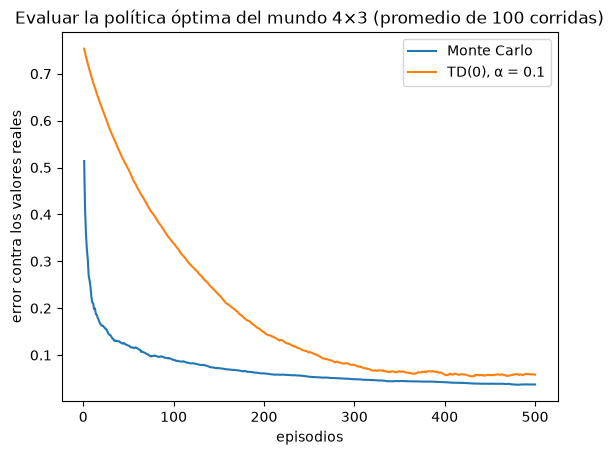

Valores reales:
  0.852    0.908    0.958       +1
  0.802        ■    0.700       -1
  0.745    0.695    0.651    0.428

Monte Carlo después de 500 episodios:
  0.877    0.931    0.972       +1
  0.815        ■    0.749       -1
  0.738    0.713    0.654    0.451

TD(0) después de 500 episodios:
  0.834    0.866    0.874       +1
  0.807        ■    0.638       -1
  0.758    0.717    0.670    0.494


In [4]:
def error(V):
    # Raíz del error cuadrático medio contra los valores reales.
    cuadrados = []
    for s in ESTADOS:
        cuadrados.append((V[s] - v_real[s]) ** 2)
    return np.sqrt(np.mean(cuadrados))

def comparar(episodios, alpha, rng):
    # Las mismas actualizaciones de la celda anterior, anotando el error después de cada episodio.
    V_mc = {s: 0.0 for s in ESTADOS}
    visitas = {s: 0 for s in ESTADOS}
    V_td = {s: 0.0 for s in ESTADOS} | {s: 0.0 for s in TERMINALES}
    errores_mc = []
    errores_td = []
    for _ in range(episodios):
        episodio = jugar_episodio(politica, rng)
        G = 0.0
        for s, r, s2 in reversed(episodio):
            G = r + GAMMA * G
            visitas[s] += 1
            V_mc[s] = V_mc[s] + (1 / visitas[s]) * (G - V_mc[s])
        for s, r, s2 in episodio:
            V_td[s] = V_td[s] + alpha * (r + GAMMA * V_td[s2] - V_td[s])
        errores_mc.append(error(V_mc))
        errores_td.append(error(V_td))
    return errores_mc, errores_td, V_mc, V_td

# 100 corridas de 500 episodios. De cada una se guarda la lista de errores, episodio por episodio.
corridas_mc = []
corridas_td = []
for corrida in range(100):
    errores_mc, errores_td, V_mc, V_td = comparar(500, alpha=0.1, rng=rng)
    corridas_mc.append(errores_mc)
    corridas_td.append(errores_td)

# El error promedio de las 100 corridas, después de cada episodio.
error_mc = np.mean(corridas_mc, axis=0)
error_td = np.mean(corridas_td, axis=0)

for k in (1, 10, 100, 500):
    print(f"después de {k:>3} episodios:  error MC {error_mc[k - 1]:.3f}   error TD {error_td[k - 1]:.3f}")

plt.plot(range(1, 501), error_mc, label="Monte Carlo")
plt.plot(range(1, 501), error_td, label="TD(0), α = 0.1")
plt.xlabel("episodios")
plt.ylabel("error contra los valores reales")
plt.title("Evaluar la política óptima del mundo 4×3 (promedio de 100 corridas)")
plt.legend()
plt.show()

# Los valores al final de la última corrida, después de 500 episodios.
print("Valores reales:")
dibujar_valores(v_real)
print("\nMonte Carlo después de 500 episodios:")
dibujar_valores(V_mc)
print("\nTD(0) después de 500 episodios:")
dibujar_valores(V_td)

### Preguntas:
En este ejemplo Monte Carlo aprende más rápido. Miren las grillas después de 10 episodios: ¿qué casillas de TD siguen cerca de 0? ¿Qué tiene que ver con cómo se propagaban los valores en la iteración de valores?

¿Por qué Monte Carlo no tiene ese problema? ¿Qué le pasa a cada estado del camino cuando termina un episodio?

Después de 10 episodios, Monte Carlo da −0.347 en (3,2), aunque el valor real es 0.700. ¿Qué pudo haber pasado en los pocos episodios que pasaron por ahí?

Con suficientes episodios, ¿los dos llegan a los mismos valores?

Si el episodio no terminara nunca (una tarea continua), ¿cuál de los dos métodos se podría usar? ¿Por qué?

# Q-LEARNING

Uno de los primeros avances en el aprendizaje por refuerzo fue el desarrollo de un algoritmo de control TD fuera de la política conocido como Q-learning (Watkins, 1989), definido por

$$
Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t) \right]
$$

donde:

- $Q(S_t, A_t)$: valor estimado de tomar la acción $A_t$ en el estado $S_t$  
- $\alpha$: tasa de aprendizaje (learning rate)  
- $R_{t+1}$: recompensa recibida tras ejecutar la acción  
- $\gamma$: factor de descuento (discount factor)  
- $\max_a Q(S_{t+1}, a)$: valor estimado máximo del siguiente estado  
- El término entre corchetes $[\,]$ es el **error de temporal-diferencia (TD error)**.


El algoritmo Q-learning es de aprendizaje por refuerzo fuera de política (off-policy). En cada paso, el agente observa el resultado de una acción, recibe una recompensa y llega a un nuevo estado, así actualiza su estimación del valor de esa acción combinando la recompensa inmediata con el valor máximo esperado de las acciones futuras. Con el tiempo, al explorar y actualizar según la fórmula de Q-learning, el agente converge hacia una política óptima que maximiza la recompensa acumulada esperada.

## Ejemplo: Q-learning en el mundo 4×3

Volvamos al mismo mundo. La iteración de valores encontró la política óptima porque conocía el modelo. Monte Carlo y TD aprendieron sin modelo, pero evaluaban una política que les dimos. Q-learning hace las dos cosas: **sin conocer el modelo y sin que le den una política**, aprende la política óptima jugando.

El agente empieza cada episodio en (1,1) y elige con ε-greedy sobre su tabla $Q$. Usamos $\alpha = 0.2$, $\varepsilon = 0.2$ y $\gamma = 1$. Al final comparamos lo aprendido con lo que dio la iteración de valores.

In [5]:
alpha = 0.2     # tasa de aprendizaje
epsilon = 0.2   # probabilidad de explorar
episodios = 2000
rng = np.random.default_rng(0)

# La tabla Q arranca en cero: un valor por cada par (estado, acción).
Q = {}
for s in ESTADOS:
    Q[s] = {}
    for a in MOVIMIENTOS:
        Q[s][a] = 0.0

pasos_por_episodio = []
for ep in range(episodios):
    s = (1, 1)
    pasos = 0
    while s not in TERMINALES:
        # Elegir la acción con ε-greedy.
        if rng.random() < epsilon:
            # Explorar: una de las cuatro acciones al azar.
            acciones = ["↑", "↓", "←", "→"]
            a = acciones[rng.integers(4)]
        else:
            # Explotar: la acción de mayor Q. Primero se busca el valor más alto...
            mejor_valor = max(Q[s].values())
            # ...después se juntan todas las acciones que llegan a ese valor (puede haber empate)...
            mejores = []
            for b in MOVIMIENTOS:
                if Q[s][b] == mejor_valor:
                    mejores.append(b)
            # ...y se elige una de ellas al azar.
            a = mejores[rng.integers(len(mejores))]

        # El entorno responde: 0.8 hacia donde se eligió, 0.1 hacia cada costado.
        s2 = paso(s, a, rng)
        r = recompensa(s2)

        # Actualización de Q-learning: hacia r + gamma max_a' Q(s', a'). Una salida vale 0.
        if s2 in TERMINALES:
            max_q_siguiente = 0.0
        else:
            max_q_siguiente = max(Q[s2].values())
        Q[s][a] = Q[s][a] + alpha * (r + GAMMA * max_q_siguiente - Q[s][a])

        s = s2
        pasos = pasos + 1
    pasos_por_episodio.append(pasos)

# Lo aprendido: en cada estado, la mejor acción según Q y su valor.
politica_q = {}
v_q = {}
for s in ESTADOS:
    mejor_accion = "↑"
    for a in MOVIMIENTOS:
        if Q[s][a] > Q[s][mejor_accion]:
            mejor_accion = a
    politica_q[s] = mejor_accion
    v_q[s] = Q[s][mejor_accion]

print("Iteración de valores (conoce el modelo):")
dibujar_valores(v_real, politica)
print(f"\nQ-learning después de {episodios} episodios (sin modelo): max_a Q(s, a) y su acción")
dibujar_valores(v_q, politica_q)

coinciden = 0
for s in ESTADOS:
    if politica_q[s] == politica[s]:
        coinciden = coinciden + 1
print(f"\nLa política aprendida coincide con la óptima en {coinciden} de {len(ESTADOS)} casillas.")

print("\nValores Q en (3,2):")
for a in MOVIMIENTOS:
    print(f"  {a}  {Q[(3, 2)][a]:+.3f}")

Iteración de valores (conoce el modelo):
 0.852→   0.908→   0.958→       +1
 0.802↑        ■   0.700↑       -1
 0.745↑   0.695←   0.651←   0.428←

Q-learning después de 2000 episodios (sin modelo): max_a Q(s, a) y su acción
 0.869→   0.890→   0.941→       +1
 0.818↑        ■   0.481←       -1
 0.757↑   0.688←   0.515←   0.405←

La política aprendida coincide con la óptima en 8 de 9 casillas.

Valores Q en (3,2):
  ↑  +0.423
  ↓  +0.479
  ←  +0.481
  →  -0.517


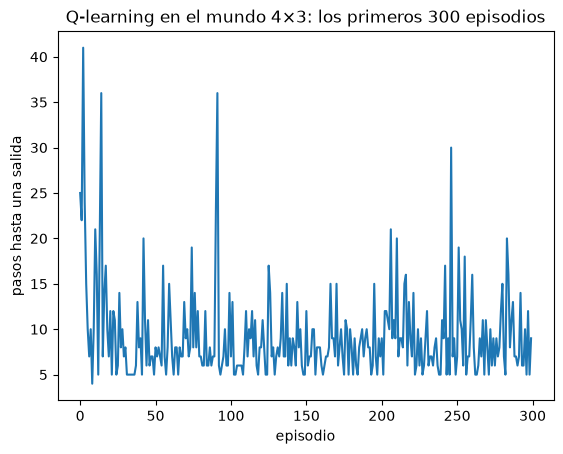

In [6]:
plt.plot(pasos_por_episodio[:300])
plt.xlabel("episodio")
plt.ylabel("pasos hasta una salida")
plt.title("Q-learning en el mundo 4×3: los primeros 300 episodios")
plt.show()

### Preguntas:
¿Por qué en los primeros episodios el agente necesita muchos pasos para llegar a una salida? ¿Qué tiene que ver con lo que vimos en TD y en la iteración de valores?

Q-learning es *off-policy*. ¿Qué política usa el agente para elegir sus acciones durante el entrenamiento, y cuál es la política que está aprendiendo?

¿En qué casilla la política aprendida no coincide con la óptima? Miren sus valores Q: ¿qué cree el agente que conviene hacer ahí? Con el modelo, subir vale 0.700 y chocar contra la pared, 0.681. ¿Por qué es fácil equivocarse justo en esa casilla? (Pista: ¿qué le pasa a la estimación de subir cada vez que el agente se desvía y cae en −1?)

Q-learning nunca usó las probabilidades 0.8 y 0.1. ¿Qué necesita la iteración de valores que Q-learning no? ¿Y qué gana la iteración de valores a cambio?

## Exploración decreciente

En el mundo 4×3 usamos un ε fijo de 0.2: el agente sigue explorando aunque ya conozca buenas acciones. Explorar mucho es útil al principio, cuando el agente no sabe nada, pero molesta al final. Una solución muy usada es empezar con un ε alto y **reducirlo con el tiempo**. Por ejemplo, de forma lineal durante los primeros $T$ pasos:

$$
\varepsilon_t = \max\left(\varepsilon_{\text{fin}},\; \varepsilon_{\text{ini}} - (\varepsilon_{\text{ini}} - \varepsilon_{\text{fin}}) \frac{t}{T}\right)
$$

Con $\varepsilon_{\text{ini}} = 1$ el agente arranca eligiendo todo al azar, y termina explorando solo una fracción $\varepsilon_{\text{fin}}$ de las veces (por ejemplo, 0.05). Lo vamos a usar en CartPole y en DQN.

# CUANDO LOS ESTADOS NO ENTRAN EN UNA TABLA

Los problemas que vimos hasta ahora tenían pocos estados: 11 en el mundo 4×3 y unos 100 en el problema del apostador. Pero en la mayoría de los problemas interesantes la cantidad de estados es enorme:

- El backgammon tiene alrededor de $10^{20}$ estados.
- En un juego de Atari el estado es la imagen de la pantalla: con 84×84 píxeles y 256 tonos de gris hay $256^{84 \cdot 84}$ imágenes posibles.
- Cuando el estado se describe con números reales (una posición, una velocidad), directamente hay **infinitos** estados.

Con una tabla hay dos problemas. El primero es de memoria: no entra. El segundo es más grave: **la tabla no generaliza**. Cada casilla se aprende por separado, así que lo aprendido en un estado no sirve para otro estado parecido. Con tantos estados, la mayoría no se visita nunca o se visita muy pocas veces.

## Ejemplo: CartPole

En CartPole hay que mantener un palo en equilibrio sobre un carrito, moviendo el carrito a la izquierda o a la derecha.

- **Estado**: 4 números reales: posición del carrito, velocidad del carrito, ángulo del palo y velocidad angular del palo.
- **Acciones**: empujar el carrito a la izquierda (0) o a la derecha (1).
- **Recompensa**: +1 por cada paso en que el palo sigue en pie.
- **Fin del episodio**: si el palo se inclina más de 12°, si el carrito se sale de la pista o si se llega a 500 pasos.

El retorno máximo, entonces, es 500.

Espacio de estados: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Espacio de acciones: Discrete(2)
Estado inicial: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]


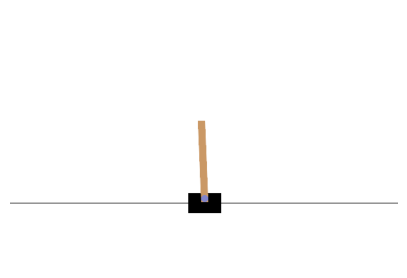

Política al azar: el palo dura en promedio 22.9 pasos


In [5]:
env = gym.make("CartPole-v1", render_mode="rgb_array")
estado, _ = env.reset(seed=0)
print("Espacio de estados:", env.observation_space)
print("Espacio de acciones:", env.action_space)
print("Estado inicial:", estado)

plt.figure(figsize=(5, 3.5))
plt.imshow(env.render())
plt.axis("off")
plt.show()

# Una política al azar, como referencia
duraciones = []
for ep in range(100):
    env.reset(seed=ep)
    total, fin = 0, False
    while not fin:
        _, r, terminado, truncado, _ = env.step(env.action_space.sample())
        total += r
        fin = terminado or truncado
    duraciones.append(total)
print(f"Política al azar: el palo dura en promedio {np.mean(duraciones):.1f} pasos")

In [3]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def animar(cuadros, titulo, cada=1):
    # Una animación con los cuadros de un episodio. Se recorre con los botones de abajo.
    # cada: cada cuántos pasos del episodio se guardó un cuadro.
    fig, ax = plt.subplots(figsize=(5, 2), dpi=60)
    imagen = ax.imshow(cuadros[0])
    ax.axis("off")

    def dibujar(k):
        imagen.set_data(cuadros[k])
        ax.set_title(f"{titulo}: paso {k * cada}")

    animacion = FuncAnimation(fig, dibujar, frames=len(cuadros), interval=100)
    plt.close(fig)
    return HTML(animacion.to_jshtml())

# Un episodio con la política al azar. Del cuadro se recorta la franja donde está el carrito.
env = gym.make("CartPole-v1", render_mode="rgb_array")
rng = np.random.default_rng(0)
env.reset(seed=0)
cuadros = [env.render()[150:320]]
fin = False
while not fin:
    _, _, terminado, truncado, _ = env.step(int(rng.integers(2)))
    cuadros.append(env.render()[150:320])
    fin = terminado or truncado
print(f"Con la política al azar, el palo se cayó a los {len(cuadros) - 1} pasos")
animar(cuadros, "al azar")

Con la política al azar, el palo se cayó a los 18 pasos


## Primer intento: discretizar

Una forma de seguir usando una tabla es **discretizar**: dividir el rango de cada variable en intervalos (*bins*) y tratar cada combinación de intervalos como un estado. Con 6 intervalos por variable hay $6^4 = 1296$ estados; con 10, hay $10^4 = 10000$.

Probemos Q-learning con las dos discretizaciones:

6 intervalos: 315 estados visitados de 1296, recompensa promedio en los últimos 100 episodios = 140


10 intervalos: 842 estados visitados de 10000, recompensa promedio en los últimos 100 episodios = 160


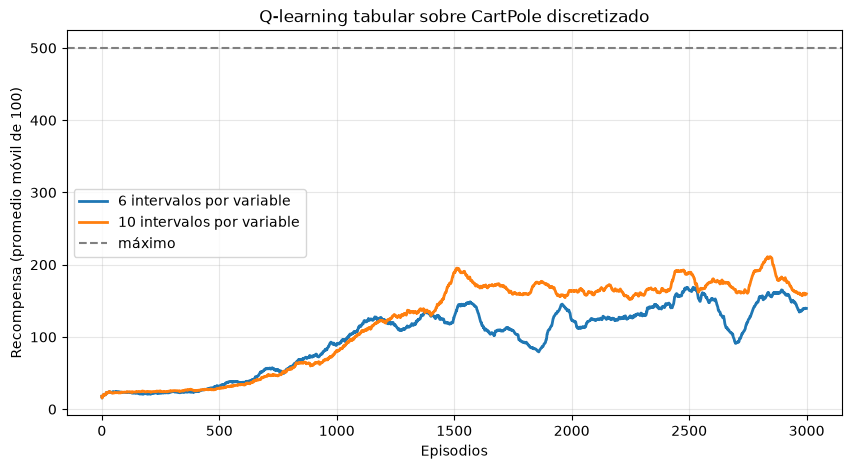

In [4]:
# Rango que se divide en intervalos para cada variable: de -límite a +límite.
# - Posición del carrito: 2.4. Si el carrito pasa de ±2.4, se sale de la pista y el episodio termina.
# - Ángulo del palo: 0.21 radianes, unos 12°. Si se inclina más, el palo se cae y el episodio termina.
# - Velocidades del carrito (3.0) y del palo (3.5): no tienen límite en el entorno. Son valores elegidos a
#   mano, que cubren casi todo lo que pasa en un episodio. Lo que se sale del rango cae en el intervalo
#   del extremo.
LIMITES = np.array([2.4, 3.0, 0.21, 3.5])

def discretizar(estado, bins):
    # Devuelve en qué intervalo cae cada una de las 4 variables, por ejemplo (3, 2, 3, 3).
    # Esa tupla es el estado de la tabla.
    indices = []
    for i in range(4):
        limite = LIMITES[i]
        x = min(max(estado[i], -limite), limite)        # lo que se sale del rango va al borde
        k = int((x + limite) / (2 * limite) * bins)     # de [-límite, límite] a 0, 1, ..., bins
        k = min(k, bins - 1)                            # x = +límite da bins: va al último intervalo
        indices.append(k)
    return tuple(indices)

def q_learning_discreto(bins, episodios=3000, alpha=0.1, gamma=0.99, semilla=0, guardar_en=()):
    # Q-learning con una tabla, como en el mundo 4x3. Devuelve la recompensa de cada episodio,
    # la tabla final y una copia de la tabla en los episodios de guardar_en.
    rng = np.random.default_rng(semilla)
    env = gym.make("CartPole-v1")
    # Un par de valores (izquierda, derecha) por estado. Los estados nunca visitados valen 0.
    Q = defaultdict(lambda: np.zeros(2))
    recompensas = []
    copias = {}
    for ep in range(episodios):
        # ε baja de 1 a 0.01 durante la primera mitad del entrenamiento.
        epsilon = max(0.01, 1.0 - ep / (episodios / 2))
        s, _ = env.reset(seed=semilla * 100_000 + ep)
        d = discretizar(s, bins)
        total = 0
        fin = False
        while not fin:
            # Elegir la acción con ε-greedy.
            if rng.random() < epsilon:
                a = int(rng.integers(2))
            else:
                a = int(np.argmax(Q[d]))

            s2, r, terminado, truncado, _ = env.step(a)
            d2 = discretizar(s2, bins)

            # Actualización de Q-learning. Si el palo se cayó, no hay valor futuro.
            if terminado:
                max_q_siguiente = 0.0
            else:
                max_q_siguiente = Q[d2].max()
            Q[d][a] = Q[d][a] + alpha * (r + gamma * max_q_siguiente - Q[d][a])

            d = d2
            total = total + r
            fin = terminado or truncado
        recompensas.append(total)
        if ep + 1 in guardar_en:
            copias[ep + 1] = {estado: valores.copy() for estado, valores in Q.items()}
    return np.array(recompensas), Q, copias

copias = {}
plt.figure(figsize=(10, 5))
for b in (6, 10):
    recompensas, Q, copias[b] = q_learning_discreto(b, guardar_en=(100, 1000, 3000))
    plt.plot(promedio_movil(recompensas, 100), label=f"{b} intervalos por variable", linewidth=2)
    print(f"{b} intervalos: {len(Q)} estados visitados de {b**4}, "
          f"recompensa promedio en los últimos 100 episodios = {recompensas[-100:].mean():.0f}")
plt.axhline(500, color="gray", linestyle="--", label="máximo")
plt.xlabel("Episodios")
plt.ylabel("Recompensa (promedio móvil de 100)")
plt.title("Q-learning tabular sobre CartPole discretizado")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### ¿Cómo se ve la tabla?

Con 6 intervalos por variable, la tabla tiene $6^4 = 1296$ estados: demasiados para mostrarla entera. Miremos una parte, los 36 estados con el carrito **cerca del centro y casi quieto** (intervalo 3 de posición y de velocidad):

- Las columnas son el **ángulo** del palo, de inclinado a la izquierda (−12°) a inclinado a la derecha (+12°).
- Las filas son la **velocidad angular**: abajo, el palo está cayendo hacia la izquierda; arriba, hacia la derecha.
- En cada casilla va la acción de mayor valor y ese valor, o un punto si el estado todavía no se visitó.

Veamos la tabla después de 100, 1000 y 3000 episodios.

In [5]:
def dibujar_tabla(tabla, bins=6, posicion=3, velocidad=3):
    # Un corte de la tabla: ángulo en las columnas y velocidad angular en las filas.
    bordes_angulo = np.degrees(np.linspace(-LIMITES[2], LIMITES[2], bins + 1))
    bordes_vel = np.linspace(-LIMITES[3], LIMITES[3], bins + 1)
    # round(...) + 0 evita que el cero se escriba como -0.
    encabezado = [f"{round(bordes_angulo[i]) + 0:+d}° a {round(bordes_angulo[i + 1]) + 0:+d}°" for i in range(bins)]
    print(" " * 16 + "".join(f"{e:>12}" for e in encabezado))
    for w in range(bins - 1, -1, -1):
        fila = []
        for angulo in range(bins):
            valores = tabla.get((posicion, velocidad, angulo, w))
            if valores is None or not valores.any():
                fila.append("·")
            else:
                accion = "←" if valores[0] > valores[1] else "→"
                fila.append(f"{accion} {valores.max():.0f}")
        print(f"{bordes_vel[w]:+5.1f} a {bordes_vel[w + 1]:+5.1f}   " + "".join(f"{c:>12}" for c in fila))

for episodio, tabla in copias[6].items():
    print(f"Después de {episodio} episodios ({len(tabla)} estados visitados en toda la tabla):")
    dibujar_tabla(tabla)
    print()

Después de 100 episodios (64 estados visitados en toda la tabla):
                  -12° a -8°   -8° a -4°   -4° a +0°   +0° a +4°   +4° a +8°  +8° a +12°
 +2.3 a  +3.5              ·           ·           ·           ·           ·           ·
 +1.2 a  +2.3              ·           ·           ·           ·           ·           ·
 +0.0 a  +1.2              ·           ·         ← 5         → 6         ← 1         → 0
 -1.2 a  +0.0            → 3         ← 4         → 7         → 7         ← 1           ·
 -2.3 a  -1.2            ← 2         ← 3         ← 2           ·           ·           ·
 -3.5 a  -2.3              ·           ·           ·           ·           ·           ·

Después de 1000 episodios (202 estados visitados en toda la tabla):
                  -12° a -8°   -8° a -4°   -4° a +0°   +0° a +4°   +4° a +8°  +8° a +12°
 +2.3 a  +3.5              ·           ·           ·           ·           ·           ·
 +1.2 a  +2.3              ·           ·           ·           ·

### Preguntas:
El agente aprende algo, pero después de 3000 episodios sigue lejos de 500. ¿Por qué no alcanza con poner más intervalos?

Dos estados con un ángulo de 0.050 y de 0.051 radianes caen a veces en intervalos distintos. ¿Qué aprende la tabla sobre uno cuando visita el otro?

En la tabla de 3000 episodios, ¿qué regla aprendió el agente? ¿Tiene sentido? ¿Por qué las casillas de arriba y de abajo siguen sin visitar?

# APROXIMACIÓN DE FUNCIONES

### Teoría:
La idea es reemplazar la tabla por una **función con parámetros** $\mathbf{w}$ que aproxime los valores de acción:

$$
\hat{q}(s, a; \mathbf{w}) \approx q_*(s, a)
$$

La función tiene muchos menos parámetros que estados, así que no puede guardar un valor independiente para cada uno. Eso es justamente lo que queremos: al ajustar $\mathbf{w}$ con la experiencia de un estado, cambian también los valores de los estados **parecidos**. La función **generaliza**.

### Aprender como un problema de regresión
En Q-learning, cada transición $(s, a, r, s')$ nos da un **objetivo** para $Q(s,a)$:

$$
y = r + \gamma \max_{a'} \hat{q}(s', a'; \mathbf{w})
$$

Queremos que $\hat{q}(s,a;\mathbf{w})$ se acerque a $y$, igual que en un problema de regresión. Usamos el error cuadrático como función de pérdida:

$$
L(\mathbf{w}) = \big( y - \hat{q}(s,a;\mathbf{w}) \big)^2
$$

y damos un paso de descenso por el gradiente:

$$
\mathbf{w} \leftarrow \mathbf{w} + \alpha \big[ y - \hat{q}(s,a;\mathbf{w}) \big] \nabla_{\mathbf{w}} \hat{q}(s,a;\mathbf{w})
$$

El término entre corchetes es el mismo **error TD** de Q-learning. De hecho, la tabla es un caso particular: un parámetro por cada par $(s,a)$, con gradiente 1 para la casilla visitada y 0 para el resto.

Un detalle: el objetivo $y$ también depende de $\mathbf{w}$, pero no lo derivamos; lo tratamos como si fuera un dato fijo. Por eso a este método se lo llama de **semi-gradiente**.

## Una red neuronal como aproximador

La función más simple es lineal en alguna representación del estado, pero es poco expresiva. En DQN se usa una **red neuronal**. Hay dos formas de armarla:

- Entrada $(s, a)$ y una salida $\hat{q}(s,a)$.
- **Entrada $s$ y una salida por cada acción**: $\hat{q}(s, a_1), \dots, \hat{q}(s, a_n)$.

Se usa la segunda, porque con una sola pasada por la red se obtienen los valores de todas las acciones, que es justo lo que hace falta para calcular el $\max$ del objetivo y para elegir la acción greedy.

Para CartPole alcanza con una red chica: 4 entradas, dos capas ocultas de 128 neuronas y 2 salidas. Ojo: en el primer intento que sigue, esta misma red **no** aprende. El problema no es el tamaño de la red sino la forma de entrenarla: más adelante, con DQN, la misma red llega a 500.

In [ ]:
def crear_red():
    return nn.Sequential(
        nn.Linear(4, 128), nn.ReLU(),
        nn.Linear(128, 128), nn.ReLU(),
        nn.Linear(128, 2),          # una salida por acción
    )

red = crear_red()
estado = torch.as_tensor(gym.make("CartPole-v1").reset(seed=0)[0])
print("Q(s, ·) =", red(estado).detach().numpy())
print("Parámetros de la red:", sum(p.numel() for p in red.parameters()))

Q(s, ·) = [-0.07908017 -0.02412491]
Parámetros de la red: 17410


# Q-LEARNING CON UNA RED: PRIMER INTENTO

La forma más directa de usar la red es reemplazar la tabla en el algoritmo de siempre: en cada paso, el agente toma una acción, observa la transición y da **un paso de gradiente con esa sola transición**, calculando el objetivo con la misma red.

Para comparar todo lo que sigue en las mismas condiciones, entrenamos siempre durante **100.000 pasos** con ε decreciente (de 1 a 0.05 en los primeros 10.000 pasos). Como función de pérdida usamos la **pérdida de Huber**, una variante del error cuadrático que se explica más adelante, en DQN.

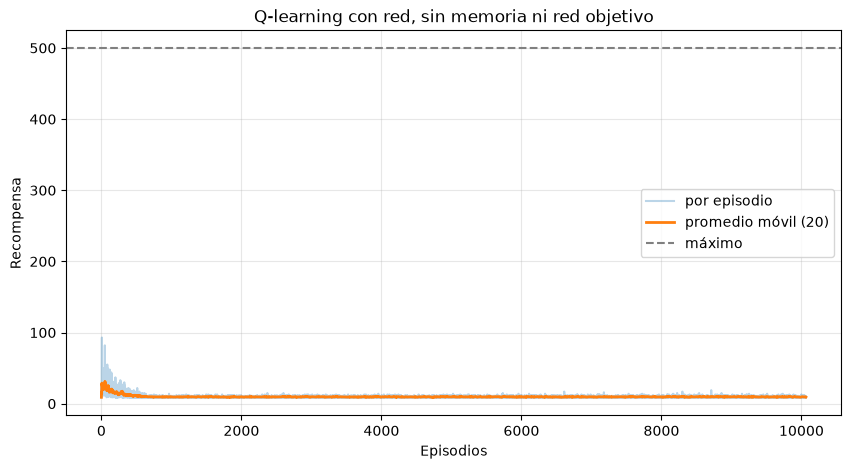

Episodios jugados: 10065, recompensa promedio en los últimos 20: 9


In [6]:
PASOS = 100_000
GAMMA = 0.99

def epsilon_lineal(paso, inicial=1.0, final=0.05, pasos_decaimiento=10_000):
    return max(final, inicial - (inicial - final) * paso / pasos_decaimiento)

def q_learning_con_red(pasos_totales=PASOS, alpha=5e-4, semilla=0):
    # Las tres fuentes de azar, con la misma semilla, para que cada corrida se pueda repetir.
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    env = gym.make("CartPole-v1")
    red = crear_red()
    optimizador = torch.optim.Adam(red.parameters(), lr=alpha)

    recompensas = []
    paso = 0           # pasos de entrenamiento, contando todos los episodios
    episodio = 0
    while paso < pasos_totales:
        s, _ = env.reset(seed=semilla * 10_000 + episodio)
        total = 0
        fin = False
        while not fin:
            # 1. Elegir acción con ε-greedy sobre la red
            if random.random() < epsilon_lineal(paso):
                a = random.randrange(env.action_space.n)
            else:
                with torch.no_grad():
                    a = int(red(torch.as_tensor(s)).argmax())

            # 2. Ejecutar la acción
            s2, r, terminado, truncado, _ = env.step(a)

            # 3. Objetivo calculado con la misma red (sin derivar: semi-gradiente).
            #    Si el palo se cayó, no hay valor futuro.
            with torch.no_grad():
                if terminado:
                    max_q_siguiente = 0.0
                else:
                    max_q_siguiente = red(torch.as_tensor(s2)).max().item()
                y = r + GAMMA * max_q_siguiente

            # 4. Un paso de gradiente con esta única transición
            q_sa = red(torch.as_tensor(s))[a]
            perdida = nn.functional.smooth_l1_loss(q_sa, torch.tensor(y))   # pérdida de Huber
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()

            s = s2
            total = total + r
            paso = paso + 1
            fin = terminado or truncado
        recompensas.append(total)
        episodio = episodio + 1
    return np.array(recompensas)

recompensas_ingenuo = q_learning_con_red()

plt.figure(figsize=(10, 5))
plt.plot(recompensas_ingenuo, alpha=0.3, label="por episodio")
plt.plot(promedio_movil(recompensas_ingenuo), linewidth=2, label="promedio móvil (20)")
plt.axhline(500, color="gray", linestyle="--", label="máximo")
plt.xlabel("Episodios")
plt.ylabel("Recompensa")
plt.title("Q-learning con red, sin memoria ni red objetivo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"Episodios jugados: {len(recompensas_ingenuo)}, "
      f"recompensa promedio en los últimos 20: {recompensas_ingenuo[-20:].mean():.0f}")

El agente no aprende. Peor todavía: después de los primeros episodios termina **peor que la política al azar**, empujando el carrito casi siempre hacia el mismo lado, y el palo cae a los pocos pasos.

## ¿Por qué falla?

Hay dos problemas, y ninguno aparecía con la tabla:

1. **Las muestras están correlacionadas.** El descenso por el gradiente supone que los ejemplos de entrenamiento son independientes. Pero acá entrenamos con transiciones consecutivas, que son casi iguales entre sí (el palo se mueve muy poco de un paso al otro). La red se ajusta demasiado a la situación del momento y, como generaliza, al hacerlo modifica los valores de todos los demás estados.
2. **El objetivo se mueve.** El objetivo $y$ se calcula con la misma red que estamos entrenando. Cada paso de gradiente cambia $\mathbf{w}$, y con eso cambia el objetivo: es como intentar alcanzar algo que se aleja cada vez que nos acercamos.

Sutton & Barto (sección 11.3) llaman **tríada mortal** (*deadly triad*) a la combinación de tres ingredientes que, juntos, pueden hacer que el aprendizaje sea inestable o directamente diverja:

- aproximación de funciones,
- *bootstrapping* (el objetivo usa estimaciones, como $\max_{a'} \hat{q}(s',a')$),
- aprendizaje *off-policy*.

Q-learning con una red tiene los tres. DQN (Mnih et al., 2015) no elimina la tríada, pero agrega dos ideas que hacen el entrenamiento mucho más estable: la memoria de repetición y la red objetivo.

# MEMORIA DE REPETICIÓN

### Teoría:
En lugar de aprender de la última transición y descartarla, el agente guarda cada transición $(s, a, r, s', \text{terminado})$ en una **memoria de repetición** (*experience replay*) de capacidad fija $N$. Cuando se llena, las más viejas se van descartando.

En cada paso, en vez de entrenar con la transición recién vivida, se toma un **minibatch** de $B$ transiciones **al azar** de la memoria y se da un paso de gradiente con el promedio de sus errores.

Esto tiene dos ventajas:

- **Rompe la correlación**: las transiciones de un minibatch vienen de momentos distintos del entrenamiento.
- **Reusa la experiencia**: cada transición se usa muchas veces, no una sola.

Esto funciona porque Q-learning es *off-policy*: aprende $q_*$ a partir de transiciones generadas por cualquier política, incluso por versiones viejas del propio agente.

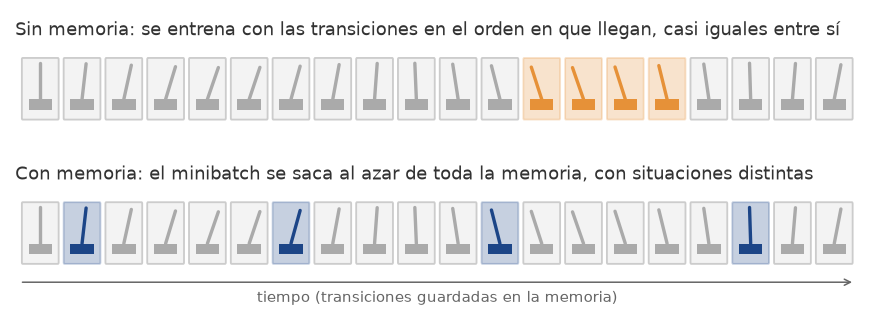

Arriba, sin memoria: se entrena con transiciones consecutivas, y el palo está casi igual en todas. Abajo, con memoria: el minibatch mezcla momentos distintos del entrenamiento.

In [7]:
class MemoriaRepeticion:
    def __init__(self, capacidad):
        self.datos = deque(maxlen=capacidad)    # al llenarse, descarta las más viejas

    def guardar(self, s, a, r, s2, terminado):
        self.datos.append((s, a, r, s2, terminado))

    def muestrear(self, tamano):
        # Elige `tamano` transiciones al azar, sin repetir.
        lote = random.sample(self.datos, tamano)
        # Separa el lote en cinco listas, una por cada parte de la transición.
        estados = []
        acciones = []
        recompensas = []
        siguientes = []
        terminados = []
        for s, a, r, s2, terminado in lote:
            estados.append(s)
            acciones.append(a)
            recompensas.append(r)
            siguientes.append(s2)
            terminados.append(terminado)
        # Las convierte en tensores, que es lo que recibe la red. Los estados quedan como una
        # tabla con una fila por transición; terminados, como 1 (sí) o 0 (no).
        S = torch.as_tensor(np.array(estados))
        A = torch.as_tensor(np.array(acciones))
        R = torch.as_tensor(np.array(recompensas), dtype=torch.float32)
        S2 = torch.as_tensor(np.array(siguientes))
        T = torch.as_tensor(np.array(terminados), dtype=torch.float32)
        return S, A, R, S2, T

    def __len__(self):
        return len(self.datos)

# Ejemplo: guardamos 5 transiciones al azar y muestreamos 3
memoria = MemoriaRepeticion(capacidad=1000)
env = gym.make("CartPole-v1")
s, _ = env.reset(seed=0)
for _ in range(5):
    a = env.action_space.sample()
    s2, r, terminado, _, _ = env.step(a)
    memoria.guardar(s, a, r, s2, terminado)
    s = s2
s, a, r, s2, terminado = memoria.muestrear(3)
print("acciones del minibatch:", a)
print("estados del minibatch:\n", s)

acciones del minibatch: tensor([0, 0, 0])
estados del minibatch:
 tensor([[ 0.0167, -0.0217, -0.0540, -0.0776],
        [ 0.0119, -0.4103, -0.0516,  0.4722],
        [ 0.0132,  0.1727, -0.0469, -0.3552]])


# RED OBJETIVO

### Teoría:
Para que el objetivo no se mueva en cada paso, DQN usa una **segunda red**, la **red objetivo**, con pesos $\mathbf{w}^-$. Es una copia de la red principal que se deja **congelada** y solo se actualiza cada $C$ pasos, copiando los pesos: $\mathbf{w}^- \leftarrow \mathbf{w}$.

El objetivo se calcula con la red objetivo:

$$
y = r + \gamma \max_{a'} \hat{q}(s', a'; \mathbf{w}^-)
$$

Durante $C$ pasos el objetivo queda fijo, y el problema se parece mucho más a una regresión común. Juntando las dos ideas, la función de pérdida que minimiza DQN es el promedio sobre transiciones sacadas de la memoria $D$:

$$
L(\mathbf{w}) = \mathbb{E}_{(s,a,r,s') \sim D} \Big[ \big( r + \gamma \max_{a'} \hat{q}(s', a'; \mathbf{w}^-) - \hat{q}(s, a; \mathbf{w}) \big)^2 \Big]
$$

# DQN

### Algoritmo
(Mnih et al., 2015)

1. Inicializar la memoria $D$ con capacidad $N$, la red $\hat{q}$ con pesos $\mathbf{w}$ al azar y la red objetivo con $\mathbf{w}^- = \mathbf{w}$.
2. En cada paso:
    1. Elegir la acción $a$ con ε-greedy sobre $\hat{q}(s, \cdot\,; \mathbf{w})$.
    2. Ejecutarla, observar $r$ y $s'$, y guardar $(s, a, r, s', \text{terminado})$ en $D$.
    3. Muestrear un minibatch de $D$ y calcular, para cada transición, $y_j = r_j$ si $s'_j$ es terminal, o $y_j = r_j + \gamma \max_{a'} \hat{q}(s'_j, a'; \mathbf{w}^-)$ si no.
    4. Dar un paso de gradiente sobre $\big(y_j - \hat{q}(s_j, a_j; \mathbf{w})\big)^2$.
    5. Cada $C$ pasos, copiar $\mathbf{w}^- \leftarrow \mathbf{w}$.

Dos detalles de la implementación:

- Se empieza a entrenar cuando la memoria ya tiene algunas transiciones (acá, 1000).
- Como en el paper, se usa la **pérdida de Huber** en vez del error cuadrático: es igual al cuadrado para errores chicos, pero crece en forma lineal para errores grandes. Así un objetivo muy desviado no produce un gradiente enorme.

La función tiene dos opciones para poder apagar cada idea por separado y ver qué aporta. Sin memoria, el minibatch es solo la última transición. Sin red objetivo, $y$ se calcula con la misma red.

Antes de la función completa, veamos con el minibatch de 3 transiciones de la memoria de ejemplo cómo se calculan el objetivo $y$ y el valor $\hat{q}(s, a)$ de la acción tomada **para todas las transiciones a la vez**. Son las mismas cuentas que el ejercicio a mano del práctico, pero con tensores. La red está sin entrenar, así que los números no significan nada: lo que importa es qué hace cada operación.

In [8]:
S, A, R, S2, T = memoria.muestrear(3)
red_ejemplo = crear_red()

with torch.no_grad():
    q_siguiente = red_ejemplo(S2)                       # una fila por transición, una columna por acción
    max_q_siguiente = q_siguiente.max(dim=1).values     # el máximo de cada fila
    y = R + GAMMA * (1 - T) * max_q_siguiente           # si s' es terminal (T = 1), no hay valor futuro
    q_todas = red_ejemplo(S)
    q_sa = q_todas.gather(1, A.unsqueeze(1)).squeeze(1)  # de cada fila, la columna de la acción tomada

print("q̂(s', ·), una fila por transición:\n", q_siguiente)
print("máximo de cada fila:", max_q_siguiente)
print("recompensas:", R, "  terminales:", T)
print("objetivo y:", y)
print()
print("q̂(s, ·), una fila por transición:\n", q_todas)
print("acciones tomadas:", A)
print("q̂(s, a) de la acción tomada:", q_sa)

q̂(s', ·), una fila por transición:
 tensor([[-0.0070, -0.0554],
        [ 0.0018, -0.0367],
        [ 0.0243, -0.0279]])
máximo de cada fila: tensor([-0.0070,  0.0018,  0.0243])
recompensas: tensor([1., 1., 1.])   terminales: tensor([0., 0., 0.])
objetivo y: tensor([0.9931, 1.0018, 1.0241])

q̂(s, ·), una fila por transición:
 tensor([[ 0.0021, -0.0360],
        [-0.0070, -0.0554],
        [ 0.0113, -0.0260]])
acciones tomadas: tensor([1, 0, 0])
q̂(s, a) de la acción tomada: tensor([-0.0360, -0.0070,  0.0113])


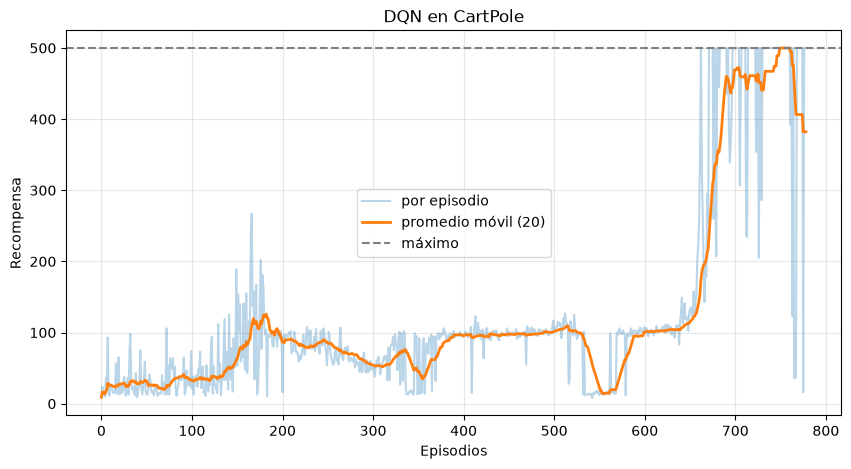

Episodios jugados: 779, recompensa promedio en los últimos 20: 382


In [9]:
def dqn(usar_memoria=True, usar_red_objetivo=True, pasos_totales=PASOS, semilla=0,
        alpha=5e-4, capacidad=10_000, tamano_lote=64, C=200, inicio=1000):
    # Las tres fuentes de azar, con la misma semilla, para que cada corrida se pueda repetir.
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    env = gym.make("CartPole-v1")
    red = crear_red()
    red_objetivo = crear_red()
    red_objetivo.load_state_dict(red.state_dict())          # w⁻ = w
    optimizador = torch.optim.Adam(red.parameters(), lr=alpha)
    # Sin memoria, la memoria guarda solo la última transición.
    if usar_memoria:
        memoria = MemoriaRepeticion(capacidad)
    else:
        memoria = MemoriaRepeticion(1)

    recompensas = []
    paso = 0           # pasos de entrenamiento, contando todos los episodios
    episodio = 0
    while paso < pasos_totales:
        s, _ = env.reset(seed=semilla * 10_000 + episodio)
        total = 0
        fin = False
        while not fin:
            # 1. Acción ε-greedy
            if random.random() < epsilon_lineal(paso):
                a = random.randrange(env.action_space.n)
            else:
                with torch.no_grad():
                    a = int(red(torch.as_tensor(s)).argmax())

            # 2. Ejecutar y guardar la transición
            s2, r, terminado, truncado, _ = env.step(a)
            memoria.guardar(s, a, r, s2, terminado)
            s = s2
            total = total + r
            paso = paso + 1
            fin = terminado or truncado

            if usar_memoria and len(memoria) < inicio:
                continue

            # 3. Minibatch y objetivo, para todas las transiciones del minibatch a la vez
            if usar_memoria:
                S, A, R, S2, T = memoria.muestrear(tamano_lote)
            else:
                S, A, R, S2, T = memoria.muestrear(1)
            with torch.no_grad():
                # El objetivo se calcula con la red objetivo, o con la misma red si no se usa.
                if usar_red_objetivo:
                    red_y = red_objetivo
                else:
                    red_y = red
                # El máximo de q̂(s', ·) de cada transición. Si s' es terminal (T = 1), se anula.
                max_q_siguiente = red_y(S2).max(dim=1).values
                y = R + GAMMA * (1 - T) * max_q_siguiente

            # 4. Paso de gradiente sobre q̂(s, a) de las acciones tomadas: gather toma, de cada
            #    fila de red(S), la columna de la acción que se tomó.
            q_sa = red(S).gather(1, A.unsqueeze(1)).squeeze(1)
            perdida = nn.functional.smooth_l1_loss(q_sa, y)    # pérdida de Huber
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()

            # 5. Cada C pasos, actualizar la red objetivo
            if usar_red_objetivo and paso % C == 0:
                red_objetivo.load_state_dict(red.state_dict())
        recompensas.append(total)
        episodio = episodio + 1
    return np.array(recompensas), red

recompensas_dqn, red_dqn = dqn()

plt.figure(figsize=(10, 5))
plt.plot(recompensas_dqn, alpha=0.3, label="por episodio")
plt.plot(promedio_movil(recompensas_dqn), linewidth=2, label="promedio móvil (20)")
plt.axhline(500, color="gray", linestyle="--", label="máximo")
plt.xlabel("Episodios")
plt.ylabel("Recompensa")
plt.title("DQN en CartPole")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"Episodios jugados: {len(recompensas_dqn)}, "
      f"recompensa promedio en los últimos 20: {recompensas_dqn[-20:].mean():.0f}")

Evaluemos la política aprendida sin explorar (ε = 0) durante 20 episodios nuevos, y miremos uno de ellos:

In [10]:
def evaluar(red, episodios=20, semilla=1234):
    env = gym.make("CartPole-v1")
    totales = []
    for ep in range(episodios):
        s, _ = env.reset(seed=semilla + ep)
        total, fin = 0, False
        while not fin:
            with torch.no_grad():
                a = int(red(torch.as_tensor(s)).argmax())
            s, r, terminado, truncado, _ = env.step(a)
            total += r
            fin = terminado or truncado
        totales.append(total)
    return np.array(totales)

totales = evaluar(red_dqn)
print(f"Recompensa en evaluación: {totales.mean():.0f} ± {totales.std():.0f} (máximo posible: 500)")

# Un episodio con la política aprendida, un cuadro cada 4 pasos.
env = gym.make("CartPole-v1", render_mode="rgb_array")
s, _ = env.reset(seed=1234)
cuadros = [env.render()[150:320]]
fin, t = False, 0
while not fin:
    with torch.no_grad():
        s, _, terminado, truncado, _ = env.step(int(red_dqn(torch.as_tensor(s)).argmax()))
    t += 1
    fin = terminado or truncado
    if t % 4 == 0:
        cuadros.append(env.render()[150:320])
animar(cuadros, "DQN", cada=4)


Recompensa en evaluación: 500 ± 0 (máximo posible: 500)


## ¿Qué aporta cada pieza?

Entrenamos las cuatro combinaciones (con y sin memoria, con y sin red objetivo), tres veces cada una con distintas semillas, siempre con 100.000 pasos. Lleva alrededor de media hora.

Mnih et al. hicieron este mismo experimento con 5 juegos de Atari: cada idea por separado mejoraba el resultado, y las dos juntas lo mejoraban muchísimo.

 sin memoria, sin red objetivo: últimos 20 episodios = 10 (por semilla: 9, 10, 9)


 sin memoria, con red objetivo: últimos 20 episodios = 104 (por semilla: 35, 71, 207)


 con memoria, sin red objetivo: últimos 20 episodios = 10 (por semilla: 10, 10, 10)


             DQN (con las dos): últimos 20 episodios = 427 (por semilla: 382, 456, 442)


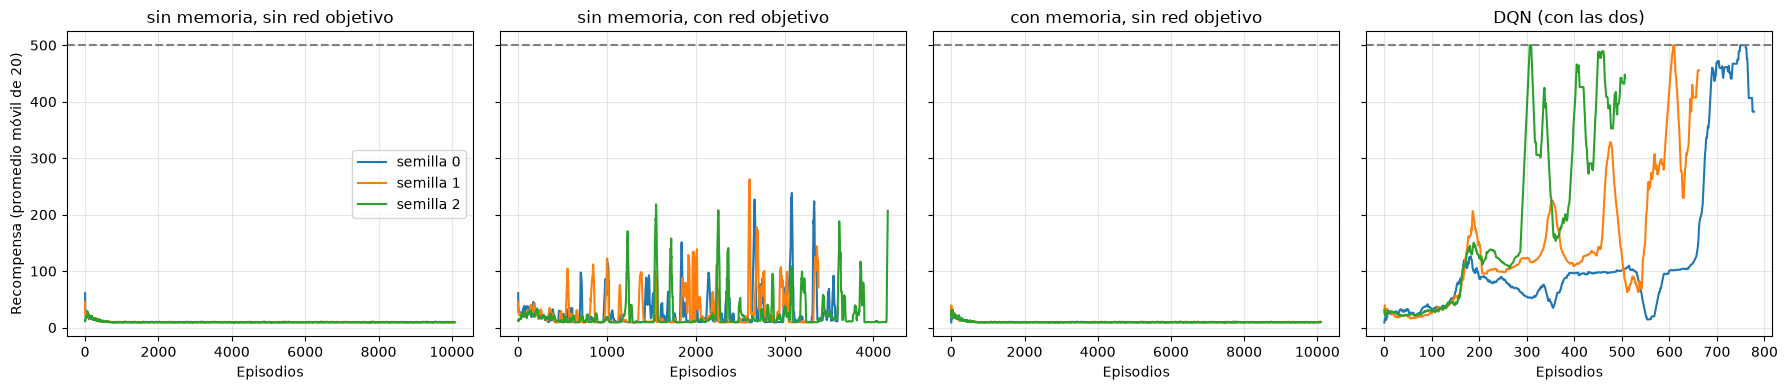

In [ ]:
variantes = {
    "sin memoria, sin red objetivo": dict(usar_memoria=False, usar_red_objetivo=False),
    "sin memoria, con red objetivo": dict(usar_memoria=False, usar_red_objetivo=True),
    "con memoria, sin red objetivo": dict(usar_memoria=True, usar_red_objetivo=False),
    "DQN (con las dos)": dict(usar_memoria=True, usar_red_objetivo=True),
}
semillas = (0, 1, 2)

resultados = {}
for nombre, opciones in variantes.items():
    resultados[nombre] = [dqn(semilla=k, **opciones)[0] for k in semillas]
    finales = [r[-20:].mean() for r in resultados[nombre]]
    print(f"{nombre:>30}: últimos 20 episodios = {np.mean(finales):.0f} "
          f"(por semilla: {', '.join(f'{f:.0f}' for f in finales)})")

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (nombre, curvas) in zip(axes, resultados.items()):
    for k, recompensas in zip(semillas, curvas):
        ax.plot(promedio_movil(recompensas), label=f"semilla {k}")
    ax.axhline(500, color="gray", linestyle="--")
    ax.set_title(nombre)
    ax.set_xlabel("Episodios")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Recompensa (promedio móvil de 20)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Preguntas:
¿Cuál de las dos ideas tiene más efecto por sí sola? ¿Por qué tiene sentido que la red objetivo sola ayude poco si las muestras siguen correlacionadas?

Las variantes que no aprenden juegan muchos más episodios en los mismos 100.000 pasos. ¿Por qué?

Mnih et al. encontraron que, en Atari, la memoria sola ya mejoraba el resultado. Acá, sin red objetivo, la memoria sola no alcanza. ¿Qué diferencias entre los dos problemas podrían explicarlo? Pensá en la cantidad de pasos de entrenamiento y en el tamaño de la red.

Aun con DQN, la curva a veces cae después de haber llegado a 500. ¿Qué parte de la tríada mortal sigue presente?

# MÁS ALLÁ DE DQN

DQN se presentó para jugar juegos de Atari a partir de la imagen de la pantalla (Mnih et al., 2015). La red recibía los últimos 4 cuadros del juego (para poder percibir movimiento), los procesaba con capas convolucionales y tenía una salida por cada botón del joystick. Con **la misma arquitectura y los mismos hiperparámetros** aprendió 49 juegos distintos, cada uno después de unos 50 millones de cuadros (unos 38 días de juego). Superó al jugador humano en 22 juegos, y en 29 de los 46 comparados alcanzó al menos el 75 % de su puntaje (Sutton & Barto, sección 16.5).

Desde entonces se propusieron muchas mejoras. La más simple es **Double DQN** (van Hasselt et al., 2016). El $\max$ del objetivo tiende a sobreestimar los valores, porque elige la acción y la evalúa con las mismas estimaciones ruidosas (es el **sesgo de maximización**, Sutton & Barto, sección 6.7). Double DQN separa las dos cosas: elige la acción con la red principal y la evalúa con la red objetivo.

$$
y = r + \gamma\, \hat{q}\big(s', \arg\max_{a'} \hat{q}(s', a'; \mathbf{w}); \mathbf{w}^-\big)
$$